# Régime d'oscillations forcées par superposition modale (mouvement d'ensemble)

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
from scipy.integrate import odeint
import scipy.fftpack
from scipy import signal
plt.rcParams['figure.figsize'] = [12, 3]
from scipy import optimize
import functools
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter

## Paramètres de la poutre

In [18]:
n_elem=5; # nombre d'éléments --> A MODIFIER
E=210000000000; # module d'Young --> A MODIFIER
rho=7800; # masse volumique --> A MODIFIER
e=0.002; # épaisseur de la lame --> A MODIFIER
b=0.015; # largeur de la lame --> A MODIFIER
l=0.3; # longueur de la lame --> A MODIFIER
ksi_rayleigh=0.01; # taux d'amortissement (visqueux) de la lame --> A MODIFIER
S=e*b; # Section de la poutre
x=np.linspace(0,l,101); # Coordonnées le long de la poutre

## Paramètres d'intégration

In [19]:
deltat=0.001; # pas de temps --> A MODIFIER
duree=1; # plage d'integration --> A MODIFIER
nb_pt=int(duree/deltat); # Discrétisation temporelle
qmax=0.02; # deplacement du point sollicite --> A MODIFIER
fmax=10; 
omega_force=10*2*np.pi;

delta_om=1; # --> A MODIFIER
om_min=1; # --> A MODIFIER
om_max=8000; # --> A MODIFIER

## Construction des matrices de masse et de raideur

\begin{equation}
\left[ M \right] =
\frac{\rho S l}{420} \left[ \begin{array}{c c c c}
156 & 22 l & 54 & -13 l \\
22 l & 4 l^2 & 13 l & -3 l^2  \\
54 & 13 l & 156 & -22 l \\
-13 l & -3 l^2 & -22 l & 4 l^2
\end{array} \right]
\end{equation}

\begin{equation}
\left[ K \right] =
\frac{EI}{l^3} \left[ \begin{array}{c c}
12 & 6 l & -12 & 6 l \\
6 l & 4 l^2 & -6 l & 2 l^2 \\
-12 & -6 l & 12 & -6 l \\
6 l & 2 l^2 & -6 l & 4 l^2
\end{array} \right]
\end{equation}

In [20]:
l_elem=l/n_elem; # longueur d'un élément
I=(b*e**3)/12;
k_elem=E*I/(l_elem**3)*np.array([[12,6*l_elem,-12,6*l_elem],[6*l_elem,4*l_elem**2,-6*l_elem,2*l_elem**2],[-12,-6*l_elem,12,-6*l_elem],[6*l_elem,2*l_elem**2,-6*l_elem,4*l_elem**2]]);
m_elem=rho*S*l_elem/420*np.array([[156,22*l_elem,54,-13*l_elem],[22*l_elem,4*l_elem**2,13*l_elem,-3*l_elem**2],[54,13*l_elem,156,-22*l_elem],[-13*l_elem,-3*l_elem**2,-22*l_elem,4*l_elem**2]]);
k_ass0=np.zeros((2*(n_elem+1),2*(n_elem+1)));
m_ass0=np.zeros((2*(n_elem+1),2*(n_elem+1)));

for j in range(n_elem):
    k_ass0[2*j:2*j+4,2*j:2*j+4]=k_ass0[2*j:2*j+4,2*j:2*j+4]+k_elem;
    m_ass0[2*j:2*j+4,2*j:2*j+4]=m_ass0[2*j:2*j+4,2*j:2*j+4]+m_elem;

k_ass=k_ass0[2:2*(n_elem+1),2:2*(n_elem+1)];
m_ass=m_ass0[2:2*(n_elem+1),2:2*(n_elem+1)];

print("k_elem",k_elem);
print("k_ass0 =",k_ass0);
print("k_ass =",k_ass);
print("m_elem =",m_elem);
print("m_ass0 =",m_ass0);
print("m_ass =",m_ass);

k_elem [[ 1.16666667e+05  3.50000000e+03 -1.16666667e+05  3.50000000e+03]
 [ 3.50000000e+03  1.40000000e+02 -3.50000000e+03  7.00000000e+01]
 [-1.16666667e+05 -3.50000000e+03  1.16666667e+05 -3.50000000e+03]
 [ 3.50000000e+03  7.00000000e+01 -3.50000000e+03  1.40000000e+02]]
k_ass0 = [[ 1.16666667e+05  3.50000000e+03 -1.16666667e+05  3.50000000e+03
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 3.50000000e+03  1.40000000e+02 -3.50000000e+03  7.00000000e+01
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [-1.16666667e+05 -3.50000000e+03  2.33333333e+05  0.00000000e+00
  -1.16666667e+05  3.50000000e+03  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 3.50000000e+03  7.00000000e+01  0.00000000e+00  2.80000000e+02
  -3.50000000e+03  7.00000000e+01  0.00000000e+00  0

## Pulsations et modes analytiques

\begin{equation}
\omega_{1} = 1.87^2 \sqrt{\frac{EI}{m l^3}}
\end{equation}

$k \in \mathbb{N}^{*} (>1)$,
\begin{equation}
\omega_{k} = \left( (2k-1) \frac{\pi}{2} \right)^2 \sqrt{\frac{EI}{m l^3}}
\end{equation}

\begin{equation}
\phi_{k}(x)=C_{1,k} \, \left( cos(\alpha_{k}(x))-ch(\alpha_{k}(x)) \right) + \frac{sin(\alpha_{k}(l))-sh(\alpha_{k}(l))}{cos(\alpha_{k}(l))+ch(\alpha_{k}(l))}\left( sin(\alpha_{k}(x))-sh(\alpha_{k}(x)) \right)
\end{equation}

Avec,
\begin{equation}
\alpha_{k}(x)=\sqrt[4]{\omega_{k}^2 \frac{\rho S}{E I}x}
\end{equation}

In [21]:
omega_ana=np.zeros((2*n_elem,1));
alpha_l=np.zeros((2*n_elem,1));
Phi_ana=np.zeros((2*n_elem,len(x)));

for k in range(2*n_elem):
    print("k =",k);
    omega_ana[k]=((2*(k+1)-1)*np.pi/2)**2*np.sqrt(E*I/rho/S/l/(l**3));
    if k==0:
        omega_ana[k]=(1.87)**2*np.sqrt(E*I/rho/S/l/(l**3));
    print("omega_ana[k] =",omega_ana[k]);
    alpha_l[k]=(omega_ana[k]**2*rho*S/E/I)**(1/4)*l;
    for j in range(len(x)):
        temp=(omega_ana[k]**2*rho*S/E/I)**(1/4)*x[j];
        Phi_ana[k,j]=(np.cos(temp)-np.cosh(temp))+(np.sin(alpha_l[k])-np.sinh(alpha_l[k]))/(np.cos(alpha_l[k])+np.cosh(alpha_l[k]))*(np.sin(temp)-np.sinh(temp));

k = 0
omega_ana[k] = [116.39717026]
k = 1
omega_ana[k] = [739.16513307]
k = 2
omega_ana[k] = [2053.23648074]
k = 3
omega_ana[k] = [4024.34350225]
k = 4
omega_ana[k] = [6652.4861976]
k = 5
omega_ana[k] = [9937.66456678]
k = 6
omega_ana[k] = [13879.8786098]
k = 7
omega_ana[k] = [18479.12832665]
k = 8
omega_ana[k] = [23735.41371735]
k = 9
omega_ana[k] = [29648.73478188]


## Résolution du problème aux valeurs propres

La détermination des pulsations propres et des modes propres consiste à résoudre le problème suivant :

\begin{equation}
det \left( \left[ M \right]^{-1} \left[ K \right] - \omega^{2}_{i} \left[ I \right] \right) = 0
\end{equation}

In [22]:
val_propres, vect_propres = la.eig(np.dot(la.inv(m_ass),k_ass)); # problème aux valeurs propres
omegar=np.sqrt(np.real(val_propres));
#print("omegar =",omegar);
o_omegar=np.argsort(omegar); # tri des modes (dans le sens croissant)
#print("o_omegar =",o_omegar);
print("omegar[o_omegar] =",omegar[o_omegar]);
print("fr[o_omegar] =",omegar[o_omegar]/2/np.pi);
print("fr_ana =",omega_ana/2/np.pi);

vps=np.concatenate((np.zeros((2,2*n_elem)),vect_propres), axis=0); # ajout des conditions aux limites
#print("vps =",vps);
print("vps[o_omegar] =",np.real(vps[:,o_omegar]));

omegar[o_omegar] = [  117.03501977   733.80266887  2061.01915053  4071.51085588
  6757.69454363 11226.39763485 16418.68443692 23810.71548585
 33824.91729029 49758.24230513]
fr[o_omegar] = [  18.62670191  116.788322    328.02138561  648.00107857 1075.52049052
 1786.7366767  2613.1147872  3789.59306813 5383.40278642 7919.27022243]
fr_ana = [[  18.52518501]
 [ 117.64178469]
 [ 326.78273525]
 [ 640.49416108]
 [1058.7760622 ]
 [1581.62843859]
 [2209.05129026]
 [2941.04461722]
 [3777.60841945]
 [4718.74269696]]
vps[o_omegar] = [[ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [-7.28548608e-03  1.25348275e-02  1.62348279e-02  1.52782156e-02
  -1.30788434e-02 -3.18649222e-03  3.38043813e-04  1.44668276e-03
   1.58

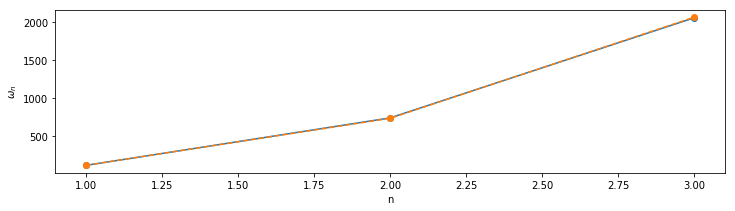

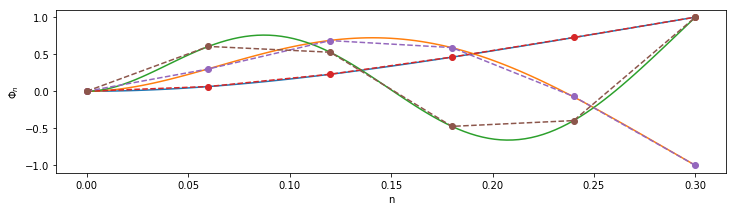

In [23]:
plt.figure();
plt.plot(range(1,4),omega_ana[0:3],'-o');
plt.plot(range(1,4),omegar[o_omegar][0:3],'--o');
plt.xlabel("n");
plt.ylabel("$\omega_{n}$");
plt.figure();
for i in range(3):
    plt.plot(x,Phi_ana[i,:]/np.max(np.abs(Phi_ana[i,:]))*np.sign(Phi_ana[i,1]),'-');
for i in range(3):
    plt.plot(np.arange(0,n_elem+1,1)/(n_elem)*l,np.real(vps[:,o_omegar][0:2*(n_elem+1):2,i])/np.max(np.abs(vps[:,o_omegar][0:2*(n_elem+1):2,i]))*np.sign(np.real(vps[:,o_omegar][2,i])),'--o');
plt.xlabel("n");
plt.ylabel("$\Phi_{n}$");

## Application des conditions initiales

Le vecteur $\left\lbrace q \right\rbrace$ s'écrit comme la combinaison linéaire des $N$ vecteurs propres $\left\lbrace x_{i=1..N} \right\rbrace$ :

\begin{equation}
\left\lbrace q \right\rbrace = \Sigma^{N}_{i=1} \eta_{i} \left\lbrace x_{i} \right\rbrace
\end{equation}

In [24]:
qq=np.zeros((2*n_elem,nb_pt));
eta=np.zeros((2*n_elem,nb_pt));

eta[:,0]=np.dot(np.linalg.inv(vps[2:2*(n_elem+1),o_omegar]),qq[:,0]);
print(eta[:,0]);

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## Affectation des paramètres et des efforts extérieurs

omega_imp =  111.18326877723032
uf [0.02 0.  ]
uf_barre [0.02 0.   0.02 0.   0.02 0.   0.02 0.   0.02 0.  ]


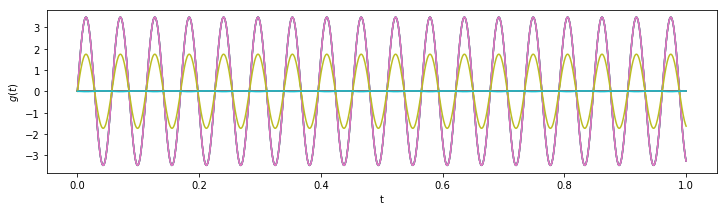

In [25]:
omega_imp=0.95*omegar[o_omegar][0]
print("omega_imp = ", omega_imp)

ksi=np.zeros((2*n_elem,1));
omegar_red=np.zeros((2*n_elem,1));
dot_eta_init=np.zeros((2*n_elem,1));
gg=np.zeros((2*n_elem,nb_pt));
t=np.linspace(0,duree,nb_pt);
for i in range(2*n_elem):
    ksi[i]=ksi_rayleigh; # taux d'amortissement
    omegar_red[i]=omegar[o_omegar][i]*np.sqrt(1-ksi[i]**2); # pulsation réduite
    dot_eta_init[i]=0; # vitesses initiales nulles
    
uf=np.array([qmax,0])
uf_barre=np.zeros((2*n_elem,))
for i in range(n_elem):
    uf_barre[2*i:2*i+2]=uf
    
print("uf",uf)
print("uf_barre",uf_barre)

for pt in range(nb_pt):
    gg[:,pt]=(np.dot(m_ass0[2:2*(n_elem+1),0:2],uf)+np.dot(m_ass,uf_barre))*np.sin(omega_imp*t[pt])*omega_imp**2;

for i in range(2*n_elem):
    plt.plot(t,gg[i,:])
plt.xlabel("t");
plt.ylabel("$g(t)$");

## Intégration numérique (transitoire)

L'équation d'équilibre est donnée par le système matriciel suivant :

\begin{equation}
\label{support}
\begin{array}{r}
\left[ \begin{array}{c c}
\left[ M_{f \, f} \right] & \left[ M_{f \, \overline{f}} \right] \\
\\
\left[ M_{\overline{f} \, f} \right] & \left[ M_{\overline{f} \, \overline{f}} \right]
\end{array} \right]
\left\lbrace
\begin{array}{c}
\left\lbrace \ddot{q}_{f} \right\rbrace \\
\\
\left\lbrace \ddot{q}_{\overline{f}} \right\rbrace
\end{array}
\right\rbrace
+
\left[ \begin{array}{c c}
\left[ C_{f \, f} \right] & \left[ C_{f \, \overline{f}} \right] \\
\\
\left[ C_{\overline{f} \, f} \right] & \left[ C_{\overline{f} \, \overline{f}} \right]
\end{array} \right]
\left\lbrace
\begin{array}{c}
\left\lbrace \dot{q}_{f} \right\rbrace \\
\\
\left\lbrace \dot{q}_{\overline{f}} \right\rbrace
\end{array}
\right\rbrace
+
\left[ \begin{array}{c c}
\left[ K_{f \, f} \right] & \left[ K_{f \, \overline{f}} \right] \\
\\
\left[ K_{\overline{f} \, f} \right] & \left[ K_{\overline{f} \, \overline{f}} \right]
\end{array} \right]
\left\lbrace
\begin{array}{c}
\left\lbrace q_{f} \right\rbrace \\
\\
\left\lbrace q_{\overline{f}} \right\rbrace
\end{array}
\right\rbrace
\\
\\
=
\left\lbrace
\begin{array}{c}
\left\lbrace g_{f}(t) \right\rbrace \\
\\
\left\lbrace g_{\overline{f}}(t) \right\rbrace
\end{array}
\right\rbrace
\end{array}
\end{equation}

Où $g_{f}$ représente les efforts de réaction du support tandis que $g_{\overline{f}}$ représente les efforts extérieurs s'exerçant sur la structure.

Le vecteur des accélérations nodales se décompose en une composante "d'entraînement" et une composante "relative" :

\begin{equation}
\begin{array}{l c c c c}
\left\lbrace \ddot{q} \right\rbrace = \left\lbrace \begin{array}{c} \left\lbrace \ddot{q}_{f} \right\rbrace \\ \left\lbrace \ddot{q}_{\overline{f}} \right\rbrace \end{array} \right\rbrace & = & \underbrace{\left\lbrace \begin{array}{c} \left\lbrace u_{f} \right\rbrace \ddot{\Phi} \\ \\ \left\lbrace u_{\overline{f}} \right\rbrace \ddot{\Phi} \end{array} \right\rbrace} & + & \underbrace{\left\lbrace \begin{array}{c} \left\lbrace 0 \right\rbrace \\ \\ \left\lbrace \ddot{q}_{r} \right\rbrace \end{array} \right\rbrace}
\\
& & accélération &  & accélération \\
& & d'entraînement &  & relative \\
\end{array}
\end{equation}

On cherche à résoudre l'équation suivante :

\begin{equation}
\left[ M_{\overline{f} \, \overline{f}} \right] \left\lbrace \ddot{q}_{r} \right\rbrace + \left[ C_{\overline{f} \, \overline{f}} \right] \left\lbrace \dot{q}_{r} \right\rbrace + \left[ K_{\overline{f} \, \overline{f}} \right] \left\lbrace q_{r} \right\rbrace = \left\lbrace g_{\overline{f}}(t) \right\rbrace - \left( \left[ M_{\overline{f} \, f} \right] \left\lbrace u_{f} \right\rbrace + \left[ M_{\overline{f} \, \overline{f}} \right] \left\lbrace u_{\overline{f}} \right\rbrace \right) \ddot{\Phi}
\end{equation}

Le changement de base permet d'obtenir pour chaque mode i ($1\le i \le n_{modes}$) :

\begin{equation}
\lambda_{i} \eta_{i} + 2 \xi_{i} \omega_{i} \dot{\eta_{i}} + \ddot{\eta_{i}} = \frac{\left\lbrace x_{i} \right\rbrace^{T} \left\lbrace F \right\rbrace}{\mu_{i}} = \frac{\left\lbrace x_{i} \right\rbrace^{T} \left\lbrace g(t) \right\rbrace}{\mu_{i}}
\end{equation}

Soit le mode $i$, la solution de l'équation différentielle associée est donnée par :

\begin{equation}
\begin{array}{l c l}
\eta_{i}(t) & = & e^{-\xi_{i}\omega_{i}t} \left[ cos \left(\omega_{i}\sqrt{1-\xi_{i}^{2}}t \right)+\frac{\xi_{i}}{\sqrt{1-\xi_{i}^{2}}} sin \left(\omega_{i}\sqrt{1-\xi_{i}^{2}}t \right) \right]\eta_{i}(0) + e^{-\xi_{i}\omega_{i}t}\left[ \frac{sin \left(\omega_{i}\sqrt{1-\xi_{i}^{2}}t \right)}{\omega_{i}\sqrt{1-\varepsilon_{i}^{2}}} \right]\dot{\eta_{i}}(0) \\ & & \\ & &
+ \int_{0}^{t} e^{-\xi_{i}\omega_{i}(t-\tau)} \frac{sin \left(\omega_{i}\sqrt{1-\xi_{i}^{2}}(t-\tau) \right)}{\omega_{i}\sqrt{1-\xi_{i}^{2}}} \frac{\left\lbrace x_{i} \right\rbrace^{T} \left\lbrace g(\tau) \right\rbrace }{\mu_{i}}d\tau
\end{array}
\end{equation}

In [26]:
mu=np.zeros((2*n_elem,1));
TT=np.zeros((2*n_elem,nb_pt));

for i in range(2*n_elem):
    print("i =",i);
    mu_temp=np.dot(m_ass,vps[2:2*(n_elem+1),o_omegar][:,i]);
    mu[i]=np.vdot(vps[2:2*(n_elem+1),o_omegar][:,i],mu_temp);
    for pt in range(nb_pt):
        print("pt =",pt);
        delta_tau=deltat;
        tau1=0;
        TT[i,pt]=0;
        for k in range(pt):
            #print("k =",k)
            f_tau1=np.exp(-ksi[i]*omegar[o_omegar][i]*(t[pt]-tau1))*np.sin(omegar_red[i]*(t[pt]-tau1))/omegar_red[i]*np.dot(vps[2:2*(n_elem+1),o_omegar][:,i],gg[:,k])/mu[i];
            f_tau2=np.exp(-ksi[i]*omegar[o_omegar][i]*(t[pt]-(tau1+delta_tau)))*np.sin(omegar_red[i]*(t[pt]-(tau1+delta_tau)))/omegar_red[i]*np.dot(vps[2:2*(n_elem+1),o_omegar][:,i],gg[:,k+1])/mu[i];
            TT[i,pt]=TT[i,pt]+delta_tau*(f_tau1+f_tau2)/2;
            tau1=tau1+delta_tau;
        eta[i,pt]=np.exp(-ksi[i]*omegar[o_omegar][i]*t[pt])*(np.cos(omegar_red[i]*t[pt])+ksi[i]/np.sqrt(1-ksi[i]**2)*np.sin(omegar_red[i]*t[pt]))*eta[i,0]+np.exp(-ksi[i]*omegar[o_omegar][i]*t[pt])/omegar_red[i]*np.sin(omegar_red[i]*t[pt])*dot_eta_init[i]+TT[i,pt];

i = 0
pt = 0
pt = 1
pt = 2
pt = 3
pt = 4
pt = 5
pt = 6
pt = 7
pt = 8
pt = 9
pt = 10
pt = 11
pt = 12
pt = 13
pt = 14
pt = 15
pt = 16
pt = 17
pt = 18
pt = 19
pt = 20
pt = 21
pt = 22
pt = 23
pt = 24
pt = 25
pt = 26
pt = 27
pt = 28
pt = 29
pt = 30
pt = 31
pt = 32
pt = 33
pt = 34
pt = 35
pt = 36
pt = 37
pt = 38
pt = 39
pt = 40
pt = 41
pt = 42
pt = 43
pt = 44
pt = 45
pt = 46
pt = 47
pt = 48
pt = 49
pt = 50
pt = 51
pt = 52
pt = 53
pt = 54
pt = 55
pt = 56
pt = 57
pt = 58
pt = 59
pt = 60
pt = 61
pt = 62
pt = 63
pt = 64
pt = 65
pt = 66
pt = 67
pt = 68
pt = 69
pt = 70
pt = 71
pt = 72
pt = 73
pt = 74
pt = 75
pt = 76
pt = 77
pt = 78
pt = 79
pt = 80
pt = 81
pt = 82
pt = 83
pt = 84
pt = 85
pt = 86
pt = 87
pt = 88
pt = 89
pt = 90
pt = 91
pt = 92
pt = 93
pt = 94
pt = 95
pt = 96
pt = 97
pt = 98
pt = 99
pt = 100
pt = 101
pt = 102
pt = 103
pt = 104
pt = 105
pt = 106
pt = 107
pt = 108
pt = 109
pt = 110
pt = 111
pt = 112
pt = 113
pt = 114
pt = 115
pt = 116
pt = 117
pt = 118
pt = 119
pt = 120
pt = 121
pt = 1

## Calcul des paramètres généralisés

Retour à la base physique de départ :

\begin{equation}
\left\lbrace q \right\rbrace = \Sigma^{N}_{i=1} \eta_{i} \left\lbrace x_{i} \right\rbrace
\end{equation}

In [27]:
for pt in range(1,nb_pt):
    qq[:,pt]=np.dot(vps[2:2*(n_elem+1),o_omegar],eta[:,pt]);
    
qf=np.zeros((2*(n_elem+1),nb_pt));
qf[2:2*(n_elem+1),:]=qq;

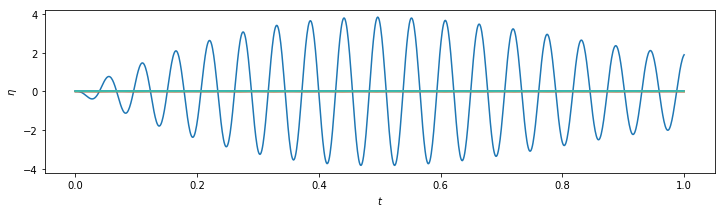

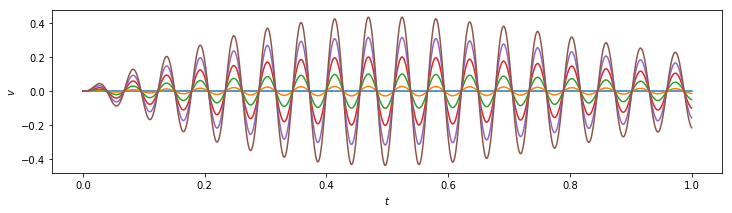

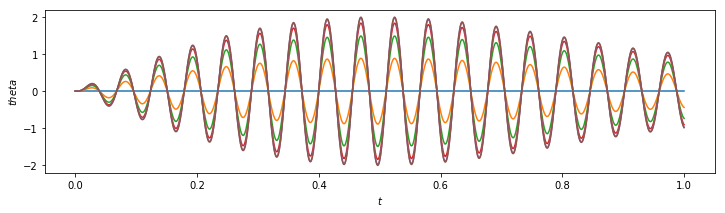

In [28]:
plt.figure();
for i in range(2*n_elem):
    plt.plot(t,eta[i,:],'-');
plt.xlabel("$t$");
plt.ylabel("$\eta$");

plt.figure();
for i in range(n_elem+1):
    plt.plot(t,qf[2*i,:],'-');
plt.xlabel("$t$");
plt.ylabel("$v$");

plt.figure()
for i in range(n_elem+1):
    plt.plot(t,qf[2*i+1,:],'-');
plt.xlabel("$t$");
plt.ylabel("$theta$");

## Matrice d'amortissement

In [29]:
alphaa=ksi_rayleigh*2*omegar[o_omegar][0];
    
c_ass0=alphaa*m_ass0;
c_ass=c_ass0[2:2*(n_elem+1),2:2*(n_elem+1)];
#print("c_ass",c_ass);

## Intégration numérique (harmonique)

On recherche une solution sous la forme suivante :

\begin{equation}
\left\lbrace q \right\rbrace = \left\lbrace q(x) \right\rbrace e^{j \omega t}
\end{equation}

D'où l'équation d'équilibre dynamique suivante :

\begin{equation}
-\omega^{2} \left[ M \right] \left\lbrace q \right\rbrace+j\omega \, \left[ C \right] \left\lbrace q \right\rbrace + \left[ K \right] \left\lbrace q \right\rbrace = \left[ S(\omega) \right] \left\lbrace q \right\rbrace = \left\lbrace a(\omega) \right\rbrace
\end{equation}

On cherche à déterminer $\left\lbrace b_{k} \right\rbrace$ pour chaque pulsation d'excitation $\omega_{k}$, avec :

\begin{equation}
\left[ S(\omega) \right] \left\lbrace b \right\rbrace = \left[ X \right]^{T} \left\lbrace a(\omega) \right\rbrace
\end{equation}

In [32]:
uf=np.array([qmax,0])
uf_barre=np.zeros((2*n_elem,))
for i in range(n_elem):
    uf_barre[2*i:2*i+2]=uf
    
print("uf",uf)
print("uf_barre",uf_barre)

om=np.arange(om_min,om_max,delta_om);
nb_pom=len(om);
qw=np.zeros((2*n_elem,nb_pom),dtype=complex);
for pom in range(nb_pom):
    print("pom =",pom);
    aa=(np.dot(m_ass0[2:2*(n_elem+1),0:2],uf)+np.dot(m_ass,uf_barre))*om[pom]**2;
    SS=k_ass-(om[pom]**2)*m_ass+1j*om[pom]*c_ass;
    invS=la.inv(SS);
    vpsa=np.dot(np.transpose(vps[2:2*(n_elem+1),o_omegar]),aa);
    bb=np.dot(invS,vpsa);
    qw[:,pom:pom+1]=np.dot(vps[2:2*(n_elem+1),o_omegar],bb).reshape(2*n_elem,1);

uf [0.02 0.  ]
uf_barre [0.02 0.   0.02 0.   0.02 0.   0.02 0.   0.02 0.  ]
pom = 0
pom = 1
pom = 2
pom = 3
pom = 4
pom = 5
pom = 6
pom = 7
pom = 8
pom = 9
pom = 10
pom = 11
pom = 12
pom = 13
pom = 14
pom = 15
pom = 16
pom = 17
pom = 18
pom = 19
pom = 20
pom = 21
pom = 22
pom = 23
pom = 24
pom = 25
pom = 26
pom = 27
pom = 28
pom = 29
pom = 30
pom = 31
pom = 32
pom = 33
pom = 34
pom = 35
pom = 36
pom = 37
pom = 38
pom = 39
pom = 40
pom = 41
pom = 42
pom = 43
pom = 44
pom = 45
pom = 46
pom = 47
pom = 48
pom = 49
pom = 50
pom = 51
pom = 52
pom = 53
pom = 54
pom = 55
pom = 56
pom = 57
pom = 58
pom = 59
pom = 60
pom = 61
pom = 62
pom = 63
pom = 64
pom = 65
pom = 66
pom = 67
pom = 68
pom = 69
pom = 70
pom = 71
pom = 72
pom = 73
pom = 74
pom = 75
pom = 76
pom = 77
pom = 78
pom = 79
pom = 80
pom = 81
pom = 82
pom = 83
pom = 84
pom = 85
pom = 86
pom = 87
pom = 88
pom = 89
pom = 90
pom = 91
pom = 92
pom = 93
pom = 94
pom = 95
pom = 96
pom = 97
pom = 98
pom = 99
pom = 100
pom = 101
pom = 102
pom 

i = 0 117.03501976550561
i = 1 733.8026688707706
i = 2 2061.0191505333505
i = 3 4071.5108558781994
i = 4 6757.694543634791


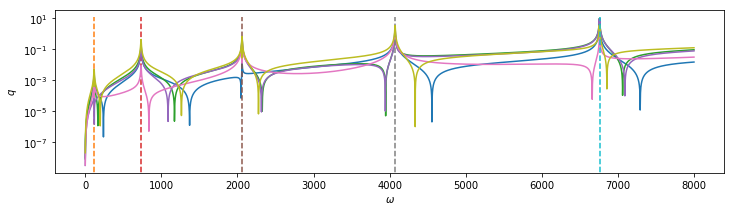

In [33]:
for i in range(n_elem):
    print("i =",i,omegar[o_omegar][i])
    plt.plot(om,np.abs(np.real(qw[2*i,:])),'-');
    plt.plot(omegar[o_omegar][i]*np.ones((2,1)),[0,1.2*np.max(np.abs(np.real(qw[::2,:])))],'--')
plt.xlabel("$\omega$");
plt.ylabel("$q$");
plt.yscale('log')